In [88]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

uploaded = files.upload()

Saving Credit_Risk_Analysis_data.csv to Credit_Risk_Analysis_data (1).csv


In [89]:
file_name = list(uploaded.keys())[0]
df = pd.read_csv(file_name)
print("Dataset shape:", df.shape)

Dataset shape: (30000, 25)


In [90]:
display(df.head())

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [91]:
print(df.columns)

Index(['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0',
       'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2',
       'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1',
       'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6',
       'default payment next month'],
      dtype='object')


In [92]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ID                          30000 non-null  int64
 1   LIMIT_BAL                   30000 non-null  int64
 2   SEX                         30000 non-null  int64
 3   EDUCATION                   30000 non-null  int64
 4   MARRIAGE                    30000 non-null  int64
 5   AGE                         30000 non-null  int64
 6   PAY_0                       30000 non-null  int64
 7   PAY_2                       30000 non-null  int64
 8   PAY_3                       30000 non-null  int64
 9   PAY_4                       30000 non-null  int64
 10  PAY_5                       30000 non-null  int64
 11  PAY_6                       30000 non-null  int64
 12  BILL_AMT1                   30000 non-null  int64
 13  BILL_AMT2                   30000 non-null  int64
 14  BILL_A

In [93]:
display(df.describe())

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,...,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.00000,30000.000000,30000.000000,30000.000000,30000.000000
mean,15000.500000,167484.322667,1.603733,1.853133,1.551867,35.485500,-0.016700,-0.133767,-0.166200,-0.220667,...,43262.948967,40311.400967,38871.760400,5663.580500,5.921163e+03,5225.68150,4826.076867,4799.387633,5215.502567,0.221200
std,8660.398374,129747.661567,0.489129,0.790349,0.521970,9.217904,1.123802,1.197186,1.196868,1.169139,...,64332.856134,60797.155770,59554.107537,16563.280354,2.304087e+04,17606.96147,15666.159744,15278.305679,17777.465775,0.415062
min,1.000000,10000.000000,1.000000,0.000000,0.000000,21.000000,-2.000000,-2.000000,-2.000000,-2.000000,...,-170000.000000,-81334.000000,-339603.000000,0.000000,0.000000e+00,0.00000,0.000000,0.000000,0.000000,0.000000
25%,7500.750000,50000.000000,1.000000,1.000000,1.000000,28.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,2326.750000,1763.000000,1256.000000,1000.000000,8.330000e+02,390.00000,296.000000,252.500000,117.750000,0.000000
50%,15000.500000,140000.000000,2.000000,2.000000,2.000000,34.000000,0.000000,0.000000,0.000000,0.000000,...,19052.000000,18104.500000,17071.000000,2100.000000,2.009000e+03,1800.00000,1500.000000,1500.000000,1500.000000,0.000000
75%,22500.250000,240000.000000,2.000000,2.000000,2.000000,41.000000,0.000000,0.000000,0.000000,0.000000,...,54506.000000,50190.500000,49198.250000,5006.000000,5.000000e+03,4505.00000,4013.250000,4031.500000,4000.000000,0.000000
max,30000.000000,1000000.000000,2.000000,6.000000,3.000000,79.000000,8.000000,8.000000,8.000000,8.000000,...,891586.000000,927171.000000,961664.000000,873552.000000,1.684259e+06,896040.00000,621000.000000,426529.000000,528666.000000,1.000000


In [94]:
print(df.isnull().sum())

ID                            0
LIMIT_BAL                     0
SEX                           0
EDUCATION                     0
MARRIAGE                      0
AGE                           0
PAY_0                         0
PAY_2                         0
PAY_3                         0
PAY_4                         0
PAY_5                         0
PAY_6                         0
BILL_AMT1                     0
BILL_AMT2                     0
BILL_AMT3                     0
BILL_AMT4                     0
BILL_AMT5                     0
BILL_AMT6                     0
PAY_AMT1                      0
PAY_AMT2                      0
PAY_AMT3                      0
PAY_AMT4                      0
PAY_AMT5                      0
PAY_AMT6                      0
default payment next month    0
dtype: int64


In [95]:
missing_percentage = (df.isnull().sum() / len(df)) * 100
print(missing_percentage)

ID                            0.0
LIMIT_BAL                     0.0
SEX                           0.0
EDUCATION                     0.0
MARRIAGE                      0.0
AGE                           0.0
PAY_0                         0.0
PAY_2                         0.0
PAY_3                         0.0
PAY_4                         0.0
PAY_5                         0.0
PAY_6                         0.0
BILL_AMT1                     0.0
BILL_AMT2                     0.0
BILL_AMT3                     0.0
BILL_AMT4                     0.0
BILL_AMT5                     0.0
BILL_AMT6                     0.0
PAY_AMT1                      0.0
PAY_AMT2                      0.0
PAY_AMT3                      0.0
PAY_AMT4                      0.0
PAY_AMT5                      0.0
PAY_AMT6                      0.0
default payment next month    0.0
dtype: float64


In [96]:
print( df.duplicated().sum())

0


In [97]:
print(df['ID'].duplicated().sum())

0


## Business question 1

 **Default status distribution**

In [98]:
print(df['default payment next month'].value_counts())

default payment next month
0    23364
1     6636
Name: count, dtype: int64


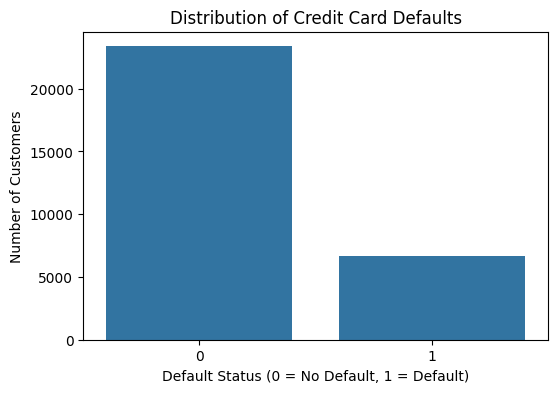

In [99]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='default payment next month')

plt.title('Distribution of Credit Card Defaults')
plt.xlabel('Default Status (0 = No Default, 1 = Default)')
plt.ylabel('Number of Customers')
plt.show()

**Default rate by gender**


In [100]:
gender_default = df.groupby('SEX')['default payment next month'].mean() * 100

print(gender_default)


SEX
1    24.167227
2    20.776281
Name: default payment next month, dtype: float64


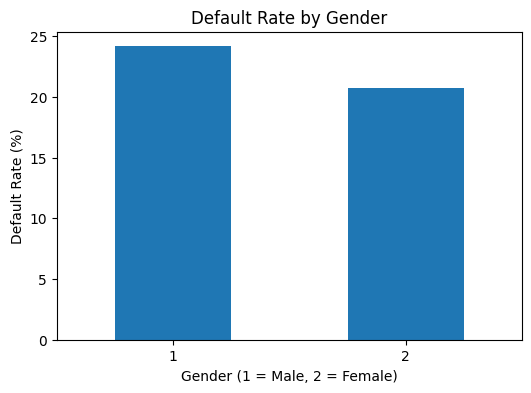

In [101]:
gender_default.plot(kind='bar', figsize=(6, 4))

plt.title('Default Rate by Gender')
plt.xlabel('Gender (1 = Male, 2 = Female)')
plt.ylabel('Default Rate (%)')
plt.xticks(rotation=0)

plt.show()

**Default rate by education**

In [102]:
education_default = df.groupby('EDUCATION')['default payment next month'].mean() * 100

print(education_default)

EDUCATION
0     0.000000
1    19.234766
2    23.734854
3    25.157616
4     5.691057
5     6.428571
6    15.686275
Name: default payment next month, dtype: float64


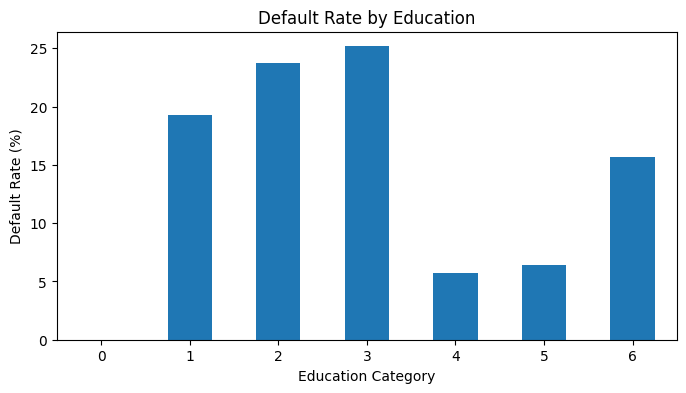

In [103]:
education_default.plot(kind='bar', figsize=(8, 4))

plt.title('Default Rate by Education')
plt.xlabel('Education Category')
plt.ylabel('Default Rate (%)')
plt.xticks(rotation=0)

plt.show()

**Default Rate by Age Group**

In [104]:
df['Age_Group'] = pd.cut(
    df['AGE'],
    bins=[0, 30, 40, 50, float('inf')],
    right=False,
    labels=['Young', 'Adult', 'Middle-Aged', 'Senior']
)

age_default = df.groupby(
    'Age_Group',
    observed=False
)['default payment next month'].mean() * 100

print("Default Rate by Age Group:")
print(age_default)


Default Rate by Age Group:
Age_Group
Young          22.842587
Adult          20.252714
Middle-Aged    22.973391
Senior         25.298507
Name: default payment next month, dtype: float64


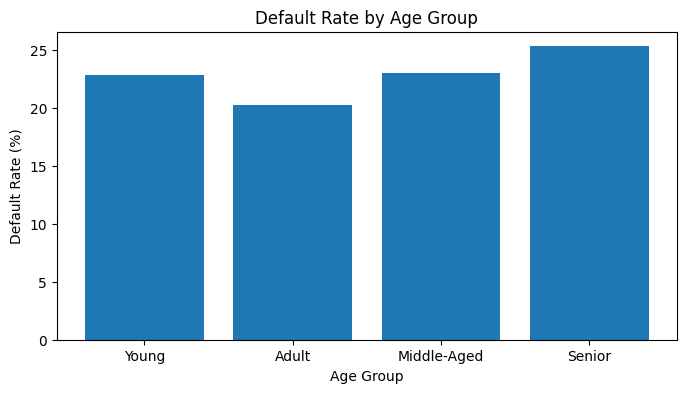

In [105]:
plt.figure(figsize=(8, 4))

plt.bar(age_default.index, age_default.values)

plt.title('Default Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Default Rate (%)')
plt.xticks(rotation=0)

plt.show()

## Business Question 2

**Credit limit distribution**

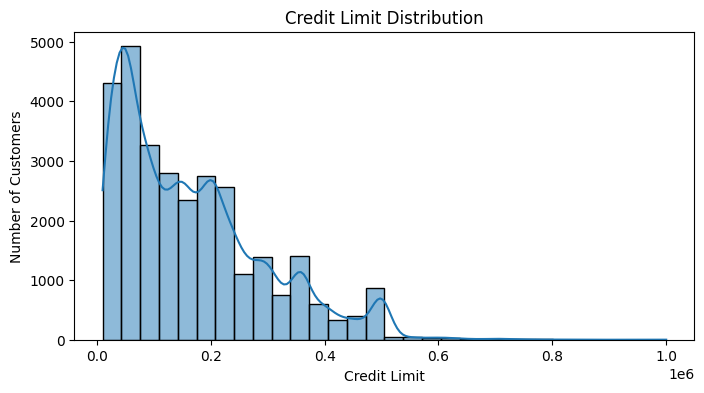

In [106]:
plt.figure(figsize=(8, 4))
sns.histplot(df['LIMIT_BAL'], bins=30, kde=True)

plt.title('Credit Limit Distribution')
plt.xlabel('Credit Limit')
plt.ylabel('Number of Customers')
plt.show()

**Default rate by credit-limit category**

In [107]:
df['Credit_Limit_Category'] = pd.cut(
    df['LIMIT_BAL'],
    bins=[-float('inf'), 50000, 150000, float('inf')],
    labels=['Low', 'Medium', 'High']
)

credit_default = df.groupby(
    'Credit_Limit_Category',
    observed=False
)['default payment next month'].mean() * 100
print(credit_default)

Credit_Limit_Category
Low       31.787389
Medium    23.716185
High      15.639706
Name: default payment next month, dtype: float64


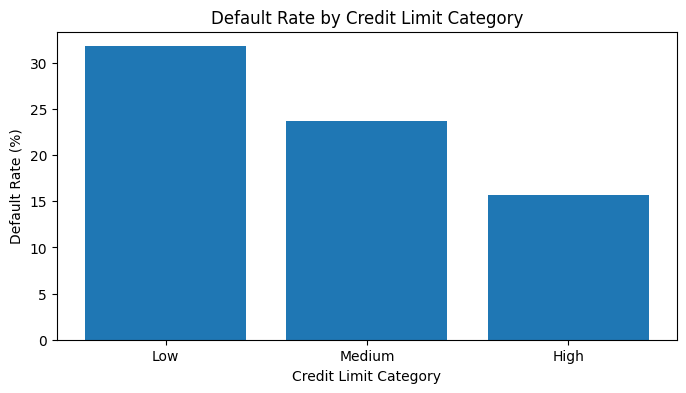

In [108]:
plt.figure(figsize=(8, 4))

plt.bar(credit_default.index, credit_default.values)

plt.title('Default Rate by Credit Limit Category')
plt.xlabel('Credit Limit Category')
plt.ylabel('Default Rate (%)')
plt.xticks(rotation=0)

plt.show()

## Business Question 3

**Repayment status vs default status heatmap**

In [109]:
repayment_heatmap = pd.crosstab(
    df['PAY_0'],
    df['default payment next month'],
    normalize='index'
) * 100

print(repayment_heatmap)



default payment next month          0          1
PAY_0                                           
-2                          86.770569  13.229431
-1                          83.221949  16.778051
 0                          87.188709  12.811291
 1                          66.052061  33.947939
 2                          30.858643  69.141357
 3                          24.223602  75.776398
 4                          31.578947  68.421053
 5                          50.000000  50.000000
 6                          45.454545  54.545455
 7                          22.222222  77.777778
 8                          42.105263  57.894737


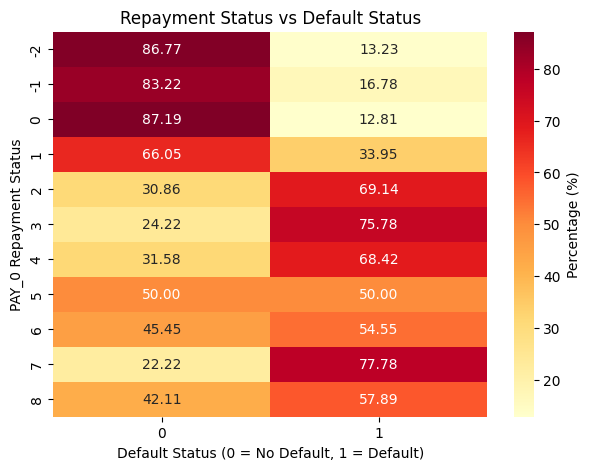

In [110]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    repayment_heatmap,
    annot=True,
    fmt='.2f',
    cmap='YlOrRd',
    cbar_kws={'label': 'Percentage (%)'}
)

plt.title('Repayment Status vs Default Status')
plt.xlabel('Default Status (0 = No Default, 1 = Default)')
plt.ylabel('PAY_0 Repayment Status')

plt.show()

## Business Question 4

**Age distribution**

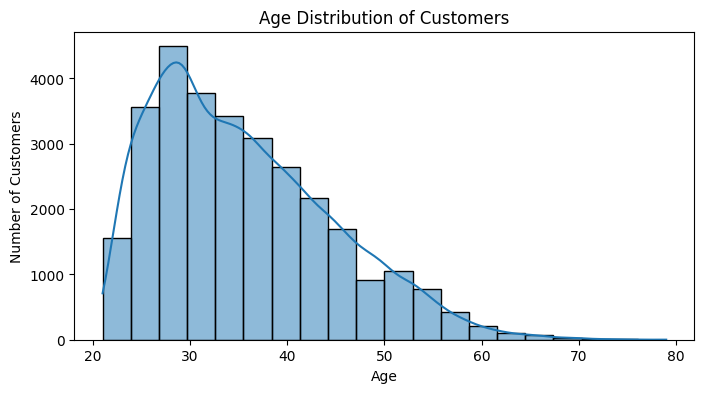

In [111]:
plt.figure(figsize=(8, 4))

sns.histplot(df['AGE'], bins=20, kde=True)

plt.title('Age Distribution of Customers')
plt.xlabel('Age')
plt.ylabel('Number of Customers')

plt.show()

## Business Question 5

**Gender distribution**

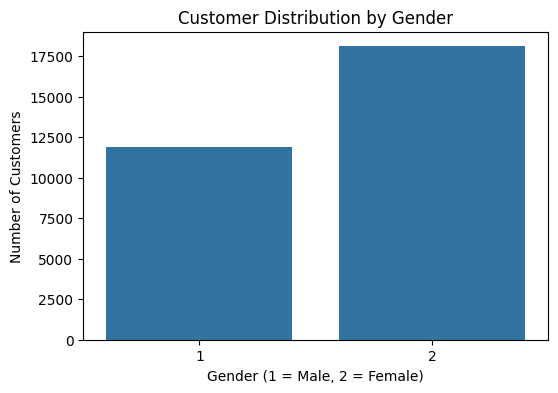

In [112]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x='SEX')

plt.title('Customer Distribution by Gender')
plt.xlabel('Gender (1 = Male, 2 = Female)')
plt.ylabel('Number of Customers')

plt.show()

**Education Distribution**

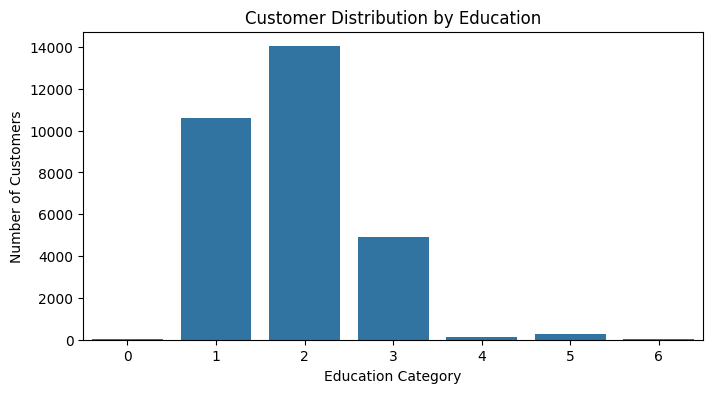

In [113]:
plt.figure(figsize=(8, 4))

sns.countplot(data=df, x='EDUCATION')

plt.title('Customer Distribution by Education')
plt.xlabel('Education Category')
plt.ylabel('Number of Customers')

plt.show()

**Marital-status distribution**

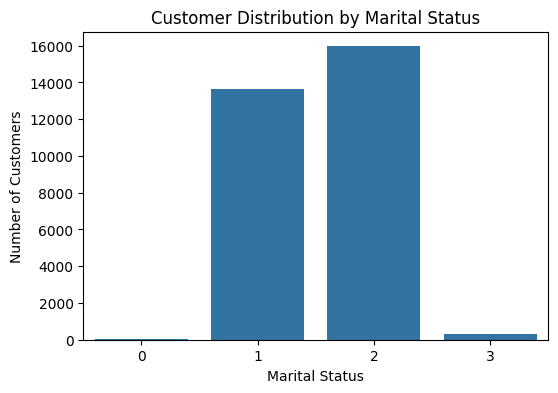

In [114]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x='MARRIAGE')

plt.title('Customer Distribution by Marital Status')
plt.xlabel('Marital Status')
plt.ylabel('Number of Customers')

plt.show()

**Default rate by marital status**

In [115]:
marital_default = df.groupby(
    'MARRIAGE'
)['default payment next month'].mean() * 100

print(marital_default)

MARRIAGE
0     9.259259
1    23.471704
2    20.928339
3    26.006192
Name: default payment next month, dtype: float64


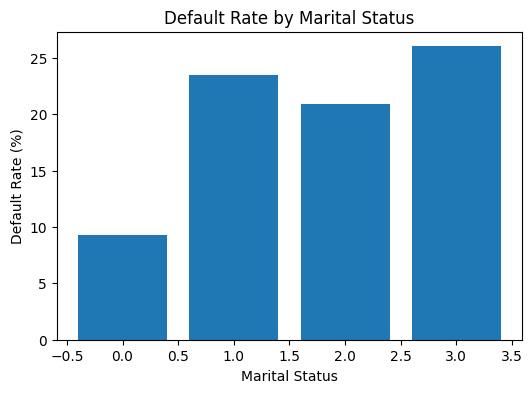

In [116]:
plt.figure(figsize=(6, 4))

plt.bar(marital_default.index, marital_default.values)

plt.title('Default Rate by Marital Status')
plt.xlabel('Marital Status')
plt.ylabel('Default Rate (%)')
plt.xticks(rotation=0)

plt.show()

## Business Question 6

**Default rate by age group and credit-limit category**

In [117]:
risk_analysis = df.pivot_table(
    index='Age_Group',
    columns='Credit_Limit_Category',
    values='default payment next month',
    aggfunc='mean',
    observed=False
) * 100

print("Default Rate by Age Group and Credit Limit:")

display(risk_analysis.round(2))

Default Rate by Age Group and Credit Limit:


Credit_Limit_Category,Low,Medium,High
Age_Group,,,
Young,30.93,22.06,14.03
Adult,32.32,24.10,14.91
Middle-Aged,32.76,25.65,16.90
Senior,32.28,25.45,20.18


**Heatmap of customer risk segments**

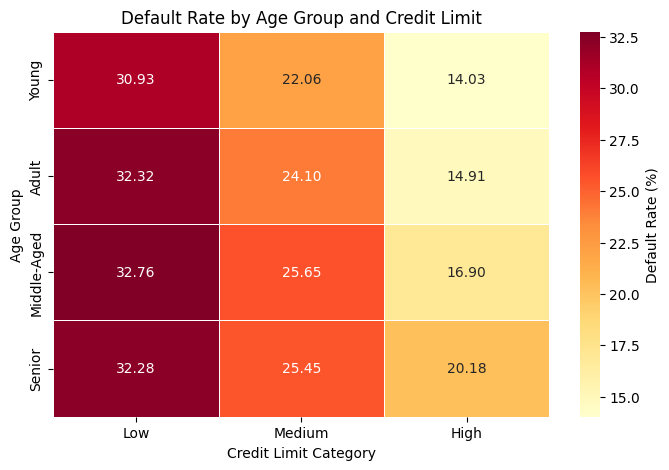

In [118]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    risk_analysis,
    annot=True,
    fmt='.2f',
    cmap='YlOrRd',
    linewidths=0.5,
    cbar_kws={'label': 'Default Rate (%)'}
)

plt.title('Default Rate by Age Group and Credit Limit')
plt.xlabel('Credit Limit Category')
plt.ylabel('Age Group')

plt.show()

**Customer count by age and credit-limit category**

In [119]:
customer_count = pd.crosstab(
    df['Age_Group'],
    df['Credit_Limit_Category']
)

print(customer_count)

Credit_Limit_Category   Low  Medium  High
Age_Group                                
Young                  3411    3377  2830
Adult                  1884    2967  6387
Middle-Aged            1560    1661  3243
Senior                  821     719  1140


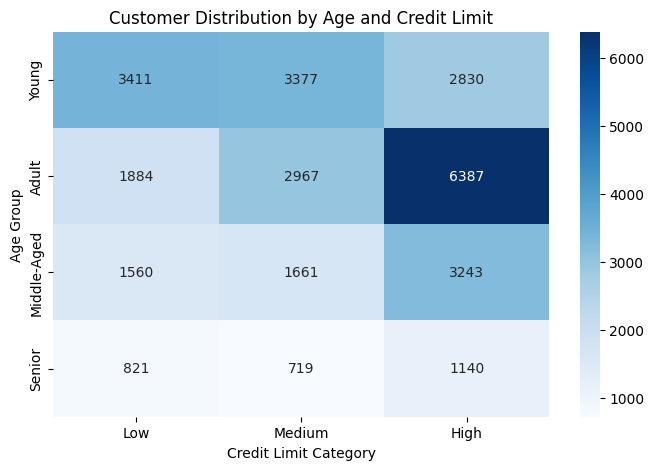

In [120]:

plt.figure(figsize=(8, 5))

sns.heatmap(
    customer_count,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title('Customer Distribution by Age and Credit Limit')
plt.xlabel('Credit Limit Category')
plt.ylabel('Age Group')

plt.show()

## Outlier Analysis

**Boxplot of credit limit**

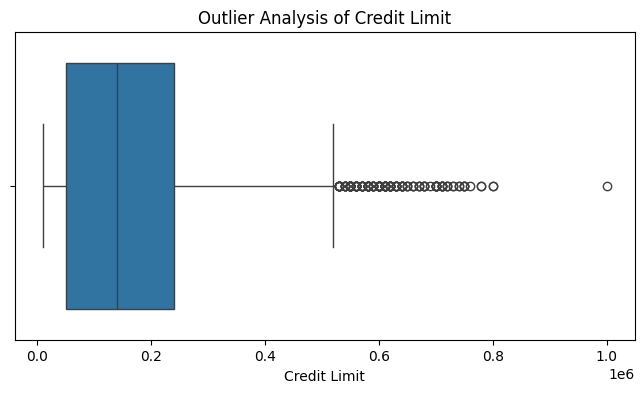

In [121]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['LIMIT_BAL'])

plt.title('Outlier Analysis of Credit Limit')
plt.xlabel('Credit Limit')
plt.show()

**Boxplot of age**

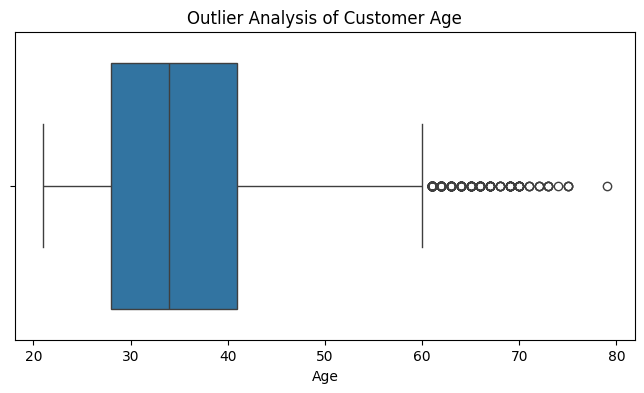

In [122]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['AGE'])

plt.title('Outlier Analysis of Customer Age')
plt.xlabel('Age')
plt.show()

**Boxplot of bill amount**

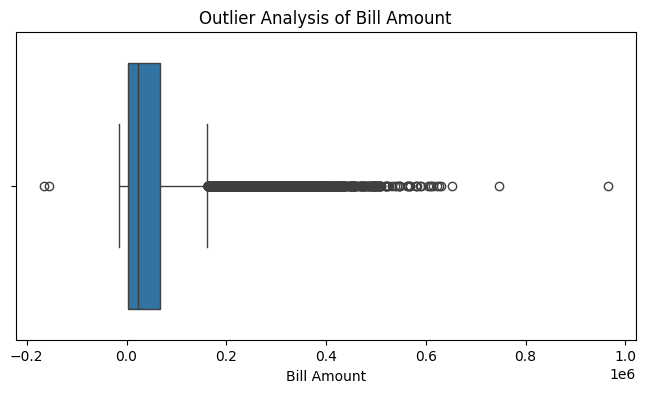

In [123]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['BILL_AMT1'])

plt.title('Outlier Analysis of Bill Amount')
plt.xlabel('Bill Amount')
plt.show()

**Boxplot of payment amount**

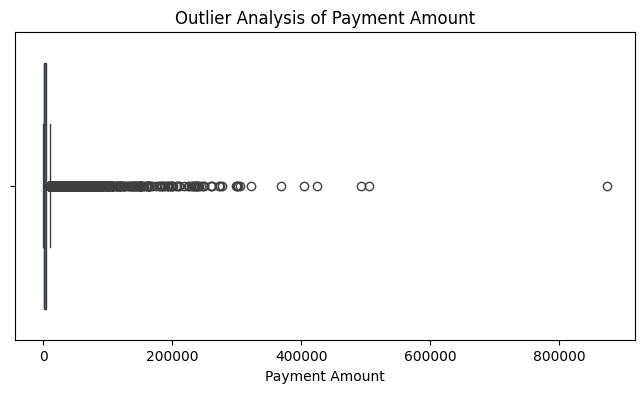

In [124]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['PAY_AMT1'])

plt.title('Outlier Analysis of Payment Amount')
plt.xlabel('Payment Amount')
plt.show()

**IQR method to identify outliers**

In [125]:
columns = ['LIMIT_BAL', 'AGE', 'BILL_AMT1', 'PAY_AMT1']

for col in columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]

    print(f"\n{col}")
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Number of Outliers:", len(outliers))


LIMIT_BAL
Lower Bound: -235000.0
Upper Bound: 525000.0
Number of Outliers: 167

AGE
Lower Bound: 8.5
Upper Bound: 60.5
Number of Outliers: 272

BILL_AMT1
Lower Bound: -91739.625
Upper Bound: 162389.375
Number of Outliers: 2400

PAY_AMT1
Lower Bound: -5009.0
Upper Bound: 11015.0
Number of Outliers: 2745


### Outlier Interpretation

- The IQR method identified potential outliers in credit limits, age, bill amounts and payment amounts. These values were retained because extreme financial values may represent genuine customer behaviour. Outliers were identified but not automatically removed.

## Correlation and association analysis

**Correlation matrix**

In [126]:
correlation_data = df.select_dtypes(include=['int64', 'float64'])
correlation_matrix = correlation_data.corr()

print("Correlation Matrix:")
display(correlation_matrix.round(2))

Correlation Matrix:


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
ID,1.00,0.03,0.02,0.04,-0.03,0.02,-0.03,-0.01,-0.02,-0.00,...,0.04,0.02,0.02,0.01,0.01,0.04,0.01,0.00,0.00,-0.01
LIMIT_BAL,0.03,1.00,0.02,-0.22,-0.11,0.14,-0.27,-0.30,-0.29,-0.27,...,0.29,0.30,0.29,0.20,0.18,0.21,0.20,0.22,0.22,-0.15
SEX,0.02,0.02,1.00,0.01,-0.03,-0.09,-0.06,-0.07,-0.07,-0.06,...,-0.02,-0.02,-0.02,-0.00,-0.00,-0.01,-0.00,-0.00,-0.00,-0.04
EDUCATION,0.04,-0.22,0.01,1.00,-0.14,0.18,0.11,0.12,0.11,0.11,...,-0.00,-0.01,-0.01,-0.04,-0.03,-0.04,-0.04,-0.04,-0.04,0.03
MARRIAGE,-0.03,-0.11,-0.03,-0.14,1.00,-0.41,0.02,0.02,0.03,0.03,...,-0.02,-0.03,-0.02,-0.01,-0.01,-0.00,-0.01,-0.00,-0.01,-0.02
AGE,0.02,0.14,-0.09,0.18,-0.41,1.00,-0.04,-0.05,-0.05,-0.05,...,0.05,0.05,0.05,0.03,0.02,0.03,0.02,0.02,0.02,0.01
PAY_0,-0.03,-0.27,-0.06,0.11,0.02,-0.04,1.00,0.67,0.57,0.54,...,0.18,0.18,0.18,-0.08,-0.07,-0.07,-0.06,-0.06,-0.06,0.32
PAY_2,-0.01,-0.30,-0.07,0.12,0.02,-0.05,0.67,1.00,0.77,0.66,...,0.22,0.22,0.22,-0.08,-0.06,-0.06,-0.05,-0.04,-0.04,0.26
PAY_3,-0.02,-0.29,-0.07,0.11,0.03,-0.05,0.57,0.77,1.00,0.78,...,0.23,0.23,0.22,0.00,-0.07,-0.05,-0.05,-0.04,-0.04,0.24
PAY_4,-0.00,-0.27,-0.06,0.11,0.03,-0.05,0.54,0.66,0.78,1.00,...,0.25,0.24,0.24,-0.01,-0.00,-0.07,-0.04,-0.03,-0.03,0.22


**Correlation heatmap**

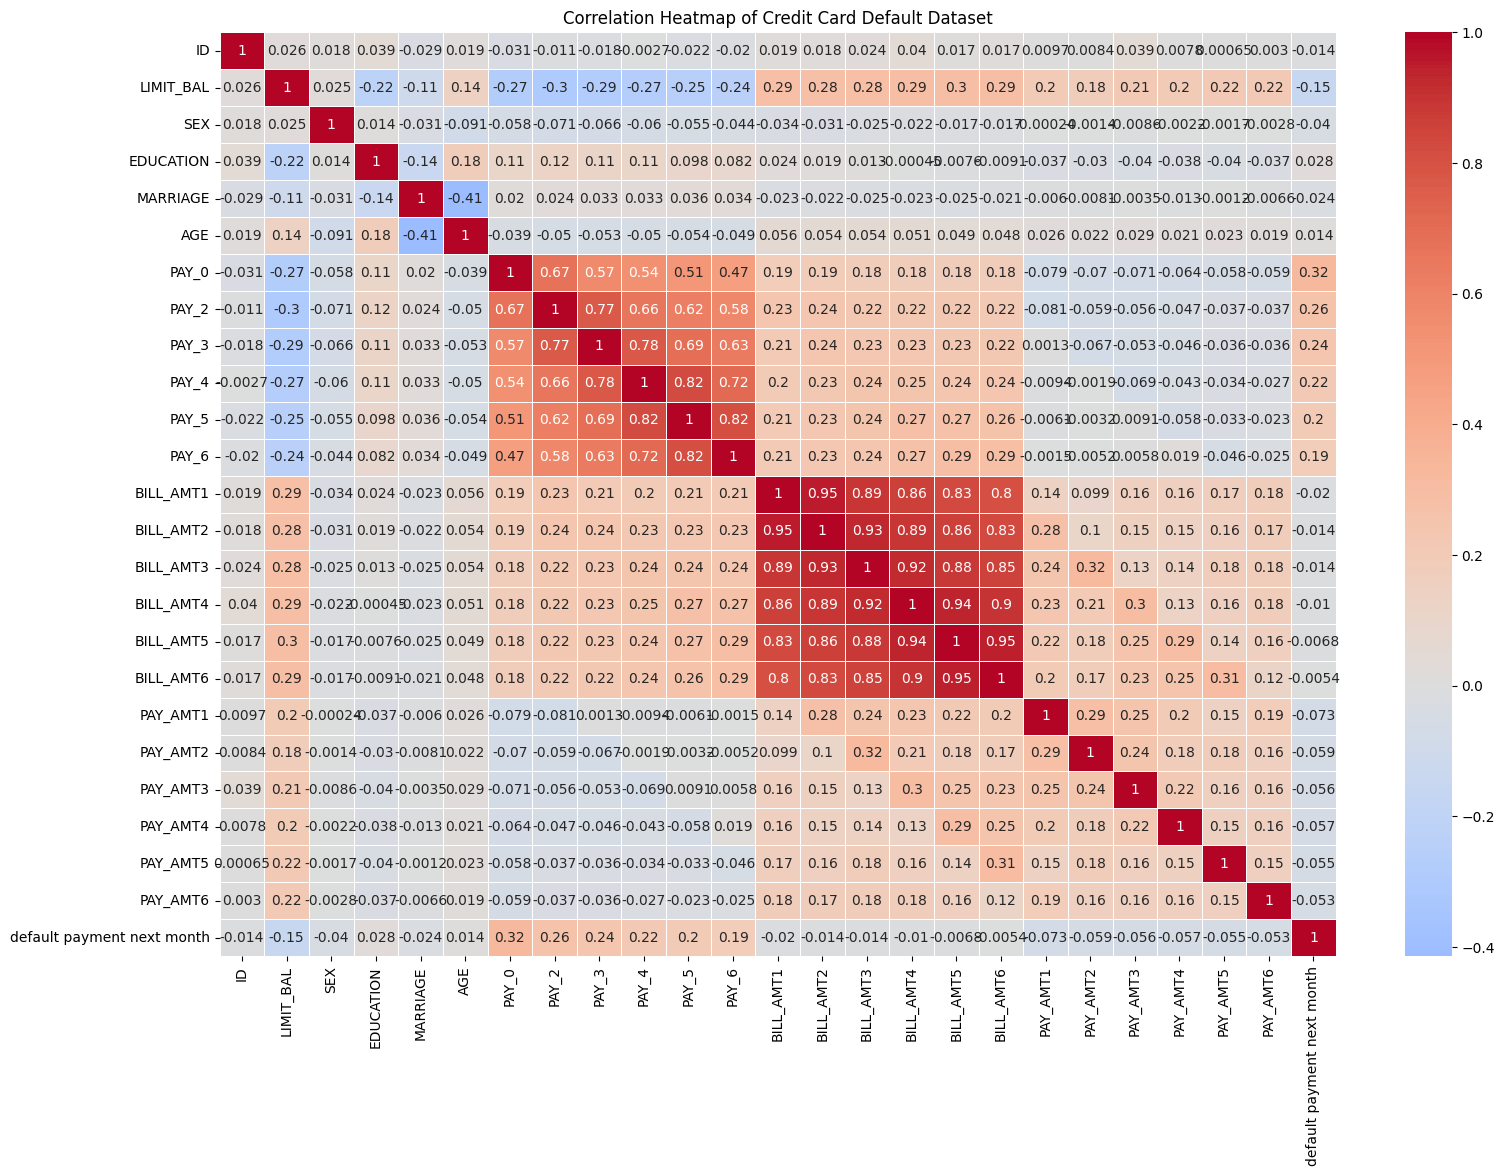

In [127]:
plt.figure(figsize=(18, 12))

sns.heatmap(
    correlation_matrix,
    cmap='coolwarm',
    annot=True,
    linewidths=0.5,
    center=0
)

plt.title('Correlation Heatmap of Credit Card Default Dataset')
plt.show()

**Correlation with default status**

In [128]:
default_correlation = correlation_matrix['default payment next month'].sort_values(ascending=False)

print("Correlation with Default Status:")
display(default_correlation)

Correlation with Default Status:


,default payment next month
default payment next month,1.000000
PAY_0,0.324794
PAY_2,0.263551
PAY_3,0.235253
PAY_4,0.216614
PAY_5,0.204149
PAY_6,0.186866
EDUCATION,0.028006
AGE,0.013890
BILL_AMT6,-0.005372


**Visualizing correlation with default status**

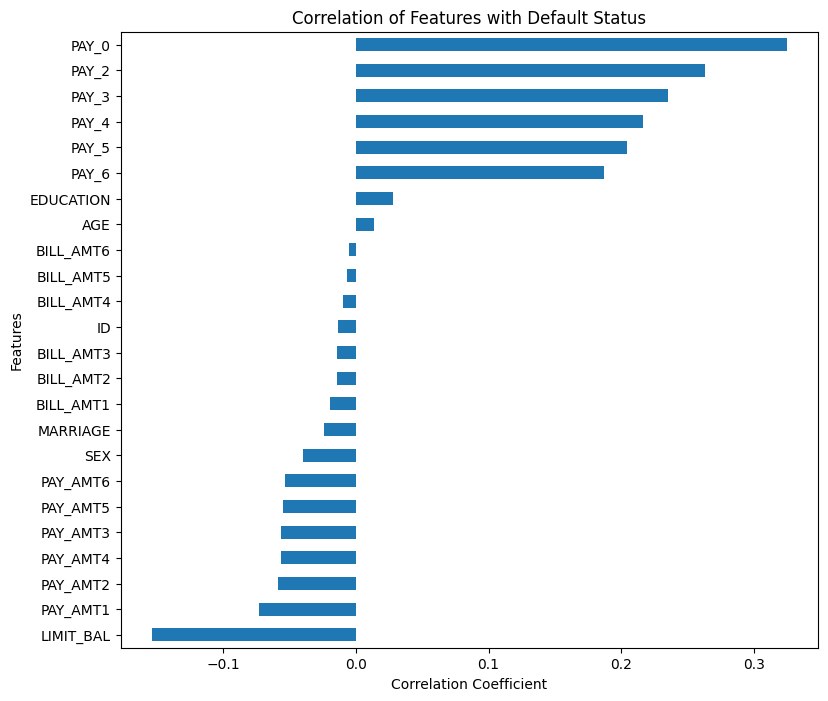

In [129]:
plt.figure(figsize=(9, 8))

default_correlation.drop(
    'default payment next month'
).sort_values().plot(kind='barh')

plt.title('Correlation of Features with Default Status')
plt.xlabel('Correlation Coefficient')
plt.ylabel('Features')
plt.show()

### Correlation Interpretation

- The correlation analysis helps identify numerical relationships between dataset variables and default status. Correlation indicates association, not causation. Categorical codes such as gender, education and marital status should not be interpreted as continuous numerical measurements.

# Business Insights and Conclusion

### 1. Customer Segmentation
- Male customers recorded a higher observed default rate (24.17%) than female customers (20.78%).
- High School education customers recorded the highest observed default rate (25.16%) among the main education categories.

### 2. Credit Limit Analysis
- Customers in the Low credit-limit category recorded a higher observed default rate (31.79%) than Medium (23.72%) and High (15.64%) categories.

### 3. Repayment Behaviour
- Customers with delayed repayment statuses generally recorded higher observed default rates.
- PAY_0 status 3 recorded a 75.78% observed default rate, while status 2 recorded 69.14%.

### 4. Age Group Analysis
- Senior customers recorded the highest observed default rate (25.30%).
- Adult customers recorded the lowest observed default rate (20.25%).

### 5. Demographic Analysis
- Observed default rates differed across gender, education and marital-status categories.
- These differences help describe the historical default patterns across customer demographics.

### 6. High-Risk Customer Segments
- The combination of age group and credit-limit category identified segments with different observed default rates.
- Middle-Aged customers with Low credit limits recorded a 32.76% observed default rate in the SQL analysis.

### Overall Conclusion
The exploratory data analysis identified patterns in customer demographics, credit limits, repayment behaviour and historical defaults. These findings can support portfolio monitoring and the development of a customer risk-segmentation framework.

The analysis describes historical observed default rates and statistical associations. It does not establish causal relationships or generate machine-learning predicted default probabilities. Further predictive modelling would be required to estimate individual customer default risk.